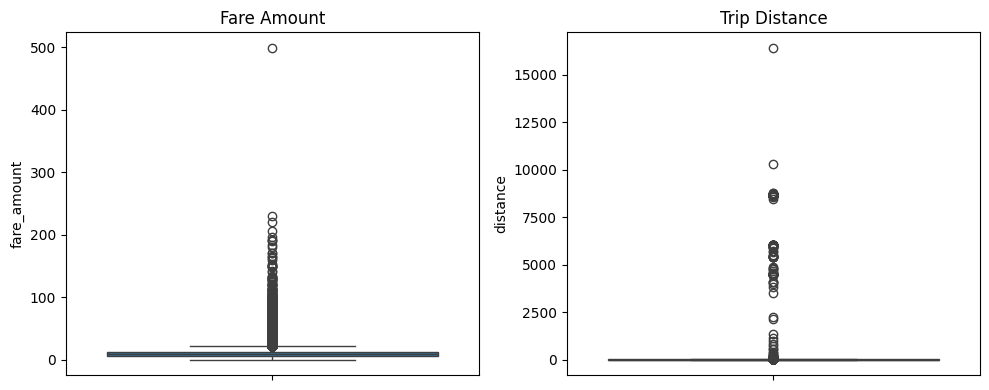

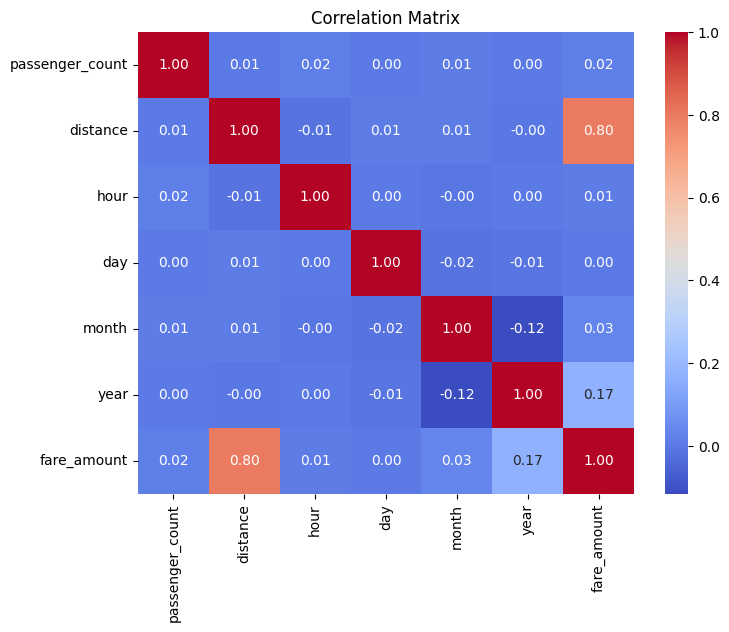


 Linear Regression
R2 Score: 0.6625
RMSE: 2.1608
MAE: 1.5351

 Ridge Regression
R2 Score: 0.6625
RMSE: 2.1608
MAE: 1.5351

 Lasso Regression
R2 Score: 0.6625
RMSE: 2.1609
MAE: 1.5355


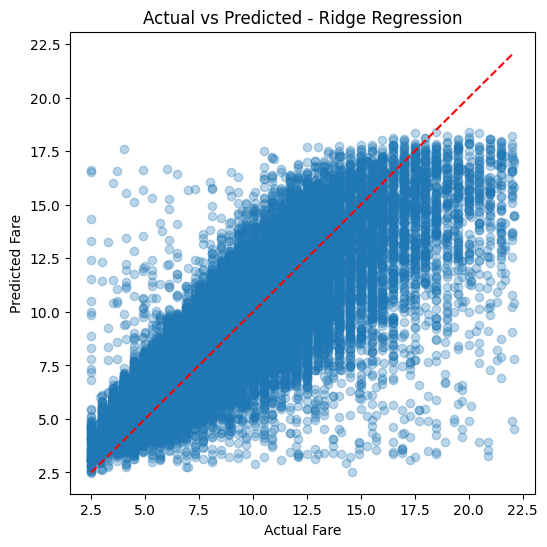

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load dataset
df = pd.read_csv("uber.csv")

# 2. Preprocessing
df = df.drop(columns=['Unnamed: 0', 'key'], errors='ignore')
df = df.dropna()

df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

# 3. Calculate distance
def haversine(lat1, lon1, lat2, lon2):
    R = 6371

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin((lon2 - lon1) / 2) ** 2
    )

    return 2 * R * np.arcsin(np.sqrt(a))

df['distance'] = haversine(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

# 4. Remove invalid records
df = df[
    (df['fare_amount'] > 0) &
    (df['distance'] > 0) &
    (df['passenger_count'].between(1, 6))
]

# 5. Visualize outliers
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['fare_amount'])
plt.title("Fare Amount")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['distance'])
plt.title("Trip Distance")

plt.tight_layout()
plt.show()

# 6. Remove outliers using IQR
for col in ['fare_amount', 'distance']:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    df = df[
        (df[col] >= Q1 - 1.5 * IQR) &
        (df[col] <= Q3 + 1.5 * IQR)
    ]

# 7. Correlation heatmap
features = [
    'passenger_count', 'distance',
    'hour', 'day', 'month', 'year'
]

corr = df[features + ['fare_amount']].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix")
plt.show()

# 8. Split dataset
X = df[features]
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 9. Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 10. Train and evaluate models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.01)
}

results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    results[name] = pred

    print("\n", name)
    print("R2 Score:", round(r2_score(y_test, pred), 4))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 4))
    print("MAE:", round(mean_absolute_error(y_test, pred), 4))

# 11. Actual vs Predicted visualization
best_model = max(
    models,
    key=lambda name: r2_score(y_test, results[name])
)

plt.figure(figsize=(6, 6))

plt.scatter(y_test, results[best_model], alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted - " + best_model)

plt.show()
